## Data preparation for Tabula Muris integration 

This script downloads data used in the scJoint [paper](https://www.nature.com/articles/s41587-021-01161-6#data-availability), originally gathered by [Cusanovich et al. 2018](https://doi.org/10.1016/j.cell.2018.06.052) (for ATAC-seq) and the [Tabula Muris Consortium, 2018](https://doi.org/10.1038/s41586-018-0590-4) (for RNA-seq). It then transforms combines these sources into a multimodal `MuData` object for later simulation.

In [ ]:
from pathlib import Path

import anndata as ad
import muon as mu
import scanpy as sc

from processing import scjoint
from processing.atac import load_atac
from processing.labels import mark_shared
from processing.mdata import build_mdata
from processing.rna import load_droplet, load_facs
from processing.sources import download, unzip

raw = Path("data/raw")
processed = Path("data/processed")

We first download and read in the tabula muris data. We drop cells that don't have any tissue or cell type annotation. 

In [ ]:
paths = download(raw)

facs = load_facs(unzip(paths["facs_counts"]), paths["facs_labels"])
droplet = load_droplet(unzip(paths["droplet_counts"]), paths["droplet_labels"])
rna = ad.concat([facs, droplet], join="outer")
atac = load_atac(paths["atac_counts"], paths["atac_cells"], paths["atac_genes"], paths["atac_labels"])

mark_shared(rna, atac)
print("RNA:", rna.shape, "ATAC:", atac.shape)
print("Eligible:", rna.obs.scjoint_eligible.sum(), atac.obs.scjoint_eligible.sum())

RNA: (100605, 23433) ATAC: (81173, 20783)
Eligible: 42228 49078


As a positive control, we'll need latent embeddings shared across the two sources. Here, we'll use the scJoint model, which is similar to the partial manifold alignment described in the original scDesign3 vignette. In particular, it allows diagonal data integration.

In [3]:
scjoint_inputs = raw / "scjoint_inputs"
scjoint_repo = raw / "scjoint"

n_genes, n_types = scjoint.write_inputs(rna, atac, scjoint_inputs)
scjoint.clone(scjoint_repo)
rna_embedding, atac_embedding = scjoint.run(scjoint_repo, scjoint_inputs, n_genes, n_types)

scjoint.add_embeddings(rna, rna_embedding)
scjoint.add_embeddings(atac, atac_embedding)

HEAD is now at cbbfa5d Update data link


Start time:  00:48:58
Training start [Stage1]
num_workers: 0
load npz matrix: /Users/krissankaran/Desktop/collaborations/scdesign/scdesigner_examples/14_tabula_muris_integration/data/raw/scjoint_inputs/rna_matrix.npz
load npz matrix: /Users/krissankaran/Desktop/collaborations/scdesign/scdesigner_examples/14_tabula_muris_integration/data/raw/scjoint_inputs/atac_matrix.npz
Epoch: 0
LR is set to 0.01
LR is set to 0.01
 [=============================>]    Step: 47ms | Tot: 8s357ms | encoding_loss: 3.976, rna_loss: 0.473 191/191 
Epoch: 1
 [=============================>]    Step: 40ms | Tot: 8s164ms | encoding_loss: 3.350, rna_loss: 0.113 191/191 
Epoch: 2
 [=============================>]    Step: 41ms | Tot: 8s190ms | encoding_loss: 3.273, rna_loss: 0.077 191/191 
Epoch: 3
 [=============================>]    Step: 42ms | Tot: 8s136ms | encoding_loss: 3.223, rna_loss: 0.053 191/191 
Epoch: 4
 [=============================>]    Step: 40ms | Tot: 8s109ms | encoding_loss: 3.181, rna_loss: 

/Users/krissankaran/Desktop/collaborations/scdesign/scdesigner_examples/14_tabula_muris_integration/data/raw/scjoint/util/closs.py:119: UserWarning: This overload of addmm_ is deprecated:
	addmm_(Number beta, Number alpha, Tensor mat1, Tensor mat2)
Consider using one of the following signatures instead:
	addmm_(Tensor mat1, Tensor mat2, *, Number beta = 1, Number alpha = 1) (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/python_arg_parser.cpp:1691.)
  distmat.addmm_(1, -2, x, self.centers.t())


 [=============================>]    Step: 45ms | Tot: 9s477ms | encoding_loss: 3.834, rna_loss: 0.951, center_loss: 1.006 191/191 ..............]    Step: 48ms | Tot: 2s35ms | encoding_loss: 5.350, rna_loss: 2.546, center_loss: 1.419 39/191 
Epoch: 1
 [=============================>]    Step: 46ms | Tot: 9s231ms | encoding_loss: 3.335, rna_loss: 0.296, center_loss: 0.785 191/191 
Epoch: 2
 [=============================>]    Step: 47ms | Tot: 10s251ms | encoding_loss: 3.299, rna_loss: 0.199, center_loss: 0.719 191/191 
Epoch: 3
 [=============================>]    Step: 49ms | Tot: 9s155ms | encoding_loss: 3.276, rna_loss: 0.148, center_loss: 0.675 191/191 
Epoch: 4
 [=============================>]    Step: 53ms | Tot: 10s49ms | encoding_loss: 3.257, rna_loss: 0.112, center_loss: 0.643 191/191  
Epoch: 5
 [=============================>]    Step: 59ms | Tot: 10s396ms | encoding_loss: 3.243, rna_loss: 0.090, center_loss: 0.621 191/191 
Epoch: 6
 [=============================>]    Ste

We can combine the processed data and embeddings into a mudata object, which we then save to disk.

In [ ]:
mdata = build_mdata(rna, atac)
processed.mkdir(parents=True, exist_ok=True)
mdata.write(processed / "tabula_muris_cusanovich.h5mu")
print(mu.read(processed / "tabula_muris_cusanovich.h5mu"))

MuData object with n_obs × n_vars = 181778 × 44216
  uns:	'modelling_distributions', 'provenance', 'scjoint_commit', 'source_studies', 'unpaired_caveat'
  2 modalities
    rna:	100605 × 23433
      obs:	'tissue', 'cell_type', 'protocol', 'scjoint_eligible', 'scjoint_1', 'scjoint_2', 'scjoint_3', 'scjoint_4', 'scjoint_5', 'scjoint_6', 'scjoint_7', 'scjoint_8', 'scjoint_9', 'scjoint_10', 'scjoint_11', 'scjoint_12', 'scjoint_13', 'scjoint_14', 'scjoint_15', 'scjoint_16', 'scjoint_17', 'scjoint_18', 'scjoint_19', 'scjoint_20', 'scjoint_21', 'scjoint_22', 'scjoint_23', 'scjoint_24', 'scjoint_25', 'scjoint_26', 'scjoint_27', 'scjoint_28', 'scjoint_29', 'scjoint_30', 'scjoint_31', 'scjoint_32', 'scjoint_33', 'scjoint_34', 'scjoint_35', 'scjoint_36', 'scjoint_37', 'scjoint_38', 'scjoint_39', 'scjoint_40', 'scjoint_41', 'scjoint_42', 'scjoint_43', 'scjoint_44', 'scjoint_45', 'scjoint_46', 'scjoint_47', 'scjoint_48', 'scjoint_49', 'scjoint_50', 'scjoint_51', 'scjoint_52', 'scjoint_53', 'scjoint_

Here's a small visual check of the scjoint embeddings. The two modalities are interspersed with each other according to cell type and tissue. 

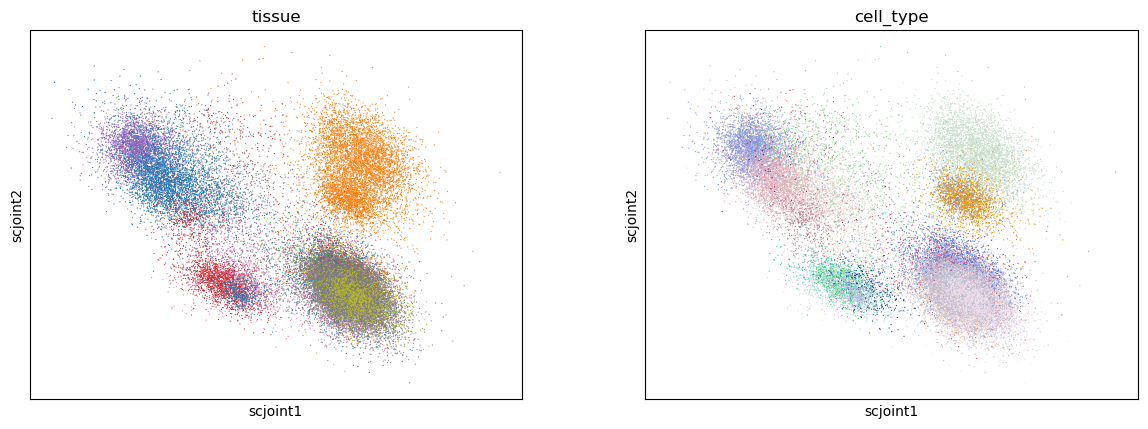

In [5]:
eligible = rna[rna.obs.scjoint_eligible.to_numpy()].copy()
eligible.strings_to_categoricals()
sc.pl.embedding(eligible, basis="scjoint", color=["tissue", "cell_type"], legend_loc=None)